# Individual Progress Review: Outlier Detection and Handling

**Student ID:** IT24100879
**Notebook:** IT24100879_Outlier_Analysis.ipynb
**Assigned Contribution:** Outlier Detection and Handling

## Dataset
This analysis uses the **Employee Performance and Productivity Data** dataset.

**Source:** https://www.kaggle.com/datasets/mexwell/employee-performance-and-productivity-data

## Objectives
- Select numerical and ordinal features suitable for outlier analysis, excluding identifiers.
- Calculate the first quartile (Q1), third quartile (Q3), and Interquartile Range (IQR).
- Flag values outside the lower and upper fences using the 1.5 × IQR rule.
- Report flagged counts and percentages without hiding results.
- Visualize feature distributions using boxplots.
- Interpret flagged values and explain the handling decision.

## Scope and Handling Decision
The IQR method identifies statistically unusual values for review. A flagged value is not automatically an error or invalid data.

The project found that no outlier removal was required. This notebook documents detection and interpretation while retaining all rows.

Summary tables, flagged counts, and visualizations will remain visible for discussion during the viva.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

def find_project_root(start_path: Path | None = None) -> Path:
    start = (start_path or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data/raw/Extended_Employee_Performance_and_Productivity_Data.csv").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")

ROOT = find_project_root()
print(f"Project root: {ROOT}")

Project root: /mnt/data/erp_upgrade/Employee_Resignation_Prediction


In [2]:
dataset_file = ROOT / "data/raw/Extended_Employee_Performance_and_Productivity_Data.csv"
if not dataset_file.is_file():
    raise FileNotFoundError(dataset_file)

df = pd.read_csv(dataset_file)
original_row_count = len(df)
print(f"Dataset file: {dataset_file.name}")
print(f"Rows: {original_row_count:,}")
print(f"Columns: {df.shape[1]}")
print("No rows have been removed.")
print("\nFirst five rows:")
display(df.head())
print("\nColumn names and data types:")
display(df.dtypes.rename("Data Type").rename_axis("Feature").to_frame())

Dataset file: Extended_Employee_Performance_and_Productivity_Data.csv
Rows: 100,000
Columns: 20
No rows have been removed.

First five rows:


,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.0,33,32,22,2,0,14,66,0,2.63,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.0,34,34,13,14,100,12,61,2,1.72,False
2,3,Finance,Male,55,Specialist,2015-10-26 08:03:05.556036,8,High School,3,5850.0,37,27,6,3,50,10,1,0,3.17,False
3,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800.0,52,10,28,12,100,10,0,1,1.86,False
4,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800.0,38,11,29,13,100,15,9,1,1.25,False



Column names and data types:


,Data Type
Feature,
Employee_ID,int64
Department,object
Gender,object
Age,int64
Job_Title,object
Hire_Date,object
Years_At_Company,int64
Education_Level,object
Performance_Score,int64


In [3]:
# Identify columns stored as numerical data.
numeric_columns = df.select_dtypes(include="number").columns.tolist()

# Exclude identifiers: their numerical values do not measure performance.
identifier_columns = [
    column
    for column in numeric_columns
    if column.lower() == "id"
    or column.lower().endswith("_id")
    or column.lower().startswith("unnamed:")
]

selected_features = [
    column
    for column in numeric_columns
    if column not in identifier_columns
]

if not selected_features:
    raise ValueError("No suitable numerical features were found.")

# Create a separate analysis copy while retaining every row.
# Numerically encoded ordinal scores are included.
numerical_df = df[selected_features].copy()

print(f"Selected features: {len(selected_features)}")
print(f"Excluded identifier columns: {identifier_columns}")
print(f"Rows retained: {len(numerical_df):,}")

# Display every selected feature and its basic characteristics.
feature_overview = pd.DataFrame({
    "Data Type": numerical_df.dtypes.astype(str),
    "Non-Missing Count": numerical_df.count(),
    "Missing Count": numerical_df.isna().sum(),
    "Unique Values": numerical_df.nunique(),
    "Minimum": numerical_df.min(),
    "Maximum": numerical_df.max()
})
feature_overview.index.name = "Feature"

with pd.option_context("display.max_rows", None):
    display(feature_overview)

print(
    "\nOrdinal scores stored numerically are included. "
    "Their ordered scale and valid range must be considered "
    "when interpreting IQR flags."
)
print("Text, date, and Boolean columns are excluded from this IQR analysis.")

assert len(numerical_df) == original_row_count, "Row count changed."

Selected features: 13
Excluded identifier columns: ['Employee_ID']
Rows retained: 100,000


,Data Type,Non-Missing Count,Missing Count,Unique Values,Minimum,Maximum
Feature,,,,,,
Age,int64,100000,0,39,22.0,60.0
Years_At_Company,int64,100000,0,11,0.0,10.0
Performance_Score,int64,100000,0,5,1.0,5.0
Monthly_Salary,float64,100000,0,28,3850.0,9000.0
Work_Hours_Per_Week,int64,100000,0,31,30.0,60.0
Projects_Handled,int64,100000,0,50,0.0,49.0
Overtime_Hours,int64,100000,0,30,0.0,29.0
Sick_Days,int64,100000,0,15,0.0,14.0
Remote_Work_Frequency,int64,100000,0,5,0.0,100.0



Ordinal scores stored numerically are included. Their ordered scale and valid range must be considered when interpreting IQR flags.
Text, date, and Boolean columns are excluded from this IQR analysis.


## IQR-Based Outlier Detection

The Interquartile Range (IQR) describes the spread of the middle 50% of non-missing values in a numerical feature.

- **Q1:** The 25th percentile.
- **Q3:** The 75th percentile.
- **IQR:** Q3 − Q1.

For each selected feature, the detection fences are:

**Lower fence = Q1 − 1.5 × IQR**

**Upper fence = Q3 + 1.5 × IQR**

A value is flagged as a potential outlier when it is strictly below the lower fence or strictly above the upper fence. Values equal to either fence are not flagged.

### Interpretation for This Dataset

Employee measurements and numerically encoded ordinal scores are assessed separately using their own fences. Flags indicate statistically unusual values; they do not establish that an employee record is incorrect.

Ordinal scores require interpretation against their permitted scale. If a feature has an IQR of zero, both fences equal Q1, so any different value is flagged and requires careful interpretation.

Missing values are excluded from quartile calculations and are not counted as outliers.

### Handling Decision

The project found that no outlier removal was required. The following cells report and visualize the flags while retaining all rows.

In [4]:
# Calculate quartiles using non-missing values in each selected feature.
q1 = numerical_df.quantile(0.25)
q3 = numerical_df.quantile(0.75)

# Calculate the IQR and detection fences.
iqr = q3 - q1
lower_fence = q1 - (1.5 * iqr)
upper_fence = q3 + (1.5 * iqr)

# Combine the calculations into a visible table.
iqr_bounds = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Lower Fence": lower_fence,
    "Upper Fence": upper_fence
})
iqr_bounds.index.name = "Feature"

print("IQR calculations for all selected features:")
with pd.option_context("display.max_rows", None):
    display(iqr_bounds)

# Flag values strictly outside the fences.
# Missing values are explicitly excluded from the flags.
below_fence = (
    numerical_df.lt(lower_fence, axis="columns")
    & numerical_df.notna()
)
above_fence = (
    numerical_df.gt(upper_fence, axis="columns")
    & numerical_df.notna()
)
outlier_flags = below_fence | above_fence

# Identify features that require special interpretation.
zero_iqr_features = iqr.index[iqr.eq(0)].tolist()
unavailable_features = iqr.index[iqr.isna()].tolist()

print(f"\nFeatures with zero IQR: {zero_iqr_features}")
print(f"Features with unavailable quartiles: {unavailable_features}")

# Verify that detection has not removed any rows.
assert len(df) == original_row_count, "Dataset row count changed."
assert len(numerical_df) == original_row_count, "Analysis row count changed."

print(f"\nAll {original_row_count:,} rows remain retained.")

IQR calculations for all selected features:


,Q1,Q3,IQR,Lower Fence,Upper Fence
Feature,,,,,
Age,31.00,51.00,20.00,1.00,81.00
Years_At_Company,2.00,7.00,5.00,-5.50,14.50
Performance_Score,2.00,4.00,2.00,-1.00,7.00
Monthly_Salary,5250.00,7500.00,2250.00,1875.00,10875.00
Work_Hours_Per_Week,37.00,53.00,16.00,13.00,77.00
Projects_Handled,12.00,37.00,25.00,-25.50,74.50
Overtime_Hours,7.00,22.00,15.00,-15.50,44.50
Sick_Days,3.00,11.00,8.00,-9.00,23.00
Remote_Work_Frequency,25.00,75.00,50.00,-50.00,150.00



Features with zero IQR: []
Features with unavailable quartiles: []

All 100,000 rows remain retained.


In [5]:
# Count flags separately below and above each feature's fences.
below_counts = below_fence.sum().astype(int)
above_counts = above_fence.sum().astype(int)
flagged_counts = outlier_flags.sum().astype(int)

# Use non-missing values as the denominator for each feature.
valid_counts = numerical_df.notna().sum()
flagged_percentages = (
    flagged_counts
    .div(valid_counts.where(valid_counts > 0))
    .mul(100)
)

# Combine IQR calculations and outlier results.
outlier_summary = iqr_bounds.copy()
outlier_summary["Non-Missing Count"] = valid_counts
outlier_summary["Missing Count"] = numerical_df.isna().sum()
outlier_summary["Below Fence Count"] = below_counts
outlier_summary["Above Fence Count"] = above_counts
outlier_summary["Total Flagged"] = flagged_counts
outlier_summary["Flagged (%)"] = flagged_percentages

# Display every feature, including features with zero flags.
print("Outlier summary for all selected features:")
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(outlier_summary.round(3))

print(
    "\nFlagged (%) = Total Flagged / Non-Missing Count × 100. "
    "Features with no non-missing values have an undefined percentage."
)
print(
    "Counts are reported per feature; one employee record may be "
    "flagged in multiple features."
)
print("No rows have been removed.")

Outlier summary for all selected features:


,Q1,Q3,IQR,Lower Fence,Upper Fence,Non-Missing Count,Missing Count,Below Fence Count,Above Fence Count,Total Flagged,Flagged (%)
Feature,,,,,,,,,,,
Age,31.00,51.00,20.00,1.00,81.00,100000,0,0,0,0,0.0
Years_At_Company,2.00,7.00,5.00,-5.50,14.50,100000,0,0,0,0,0.0
Performance_Score,2.00,4.00,2.00,-1.00,7.00,100000,0,0,0,0,0.0
Monthly_Salary,5250.00,7500.00,2250.00,1875.00,10875.00,100000,0,0,0,0,0.0
Work_Hours_Per_Week,37.00,53.00,16.00,13.00,77.00,100000,0,0,0,0,0.0
Projects_Handled,12.00,37.00,25.00,-25.50,74.50,100000,0,0,0,0,0.0
Overtime_Hours,7.00,22.00,15.00,-15.50,44.50,100000,0,0,0,0,0.0
Sick_Days,3.00,11.00,8.00,-9.00,23.00,100000,0,0,0,0,0.0
Remote_Work_Frequency,25.00,75.00,50.00,-50.00,150.00,100000,0,0,0,0,0.0



Flagged (%) = Total Flagged / Non-Missing Count × 100. Features with no non-missing values have an undefined percentage.
Counts are reported per feature; one employee record may be flagged in multiple features.
No rows have been removed.


In [6]:
# Display flagged counts for every selected feature, including zero counts.
flagged_count_table = (
    outlier_flags.sum()
    .astype(int)
    .rename("Flagged Count")
    .sort_values(ascending=False)
    .to_frame()
)
flagged_count_table.index.name = "Feature"

print("Flagged counts per feature:")
with pd.option_context("display.max_rows", None):
    display(flagged_count_table)

# Count distinct rows flagged in at least one selected feature.
rows_with_flags = outlier_flags.any(axis=1)
distinct_flagged_rows = int(rows_with_flags.sum())
total_flagged_values = int(outlier_flags.sum().sum())
unflagged_rows = len(df) - distinct_flagged_rows

flagged_row_percentage = (
    100 * distinct_flagged_rows / len(df)
    if len(df) > 0
    else float("nan")
)

print(f"\nTotal flagged values across features: {total_flagged_values:,}")
print(f"Distinct rows with at least one flag: {distinct_flagged_rows:,}")
print(f"Percentage of rows with at least one flag: {flagged_row_percentage:.2f}%")
print(f"Rows with no flags: {unflagged_rows:,}")

print(
    "\nA row flagged in multiple features contributes multiple flagged "
    "values but is counted only once in the distinct flagged row total."
)

# Confirm that flagging has not changed the dataset.
assert len(df) == original_row_count, "Dataset row count changed."
assert len(numerical_df) == original_row_count, "Analysis row count changed."

print(f"\nRows retained: {len(df):,} of {original_row_count:,}")
print("No outlier removal has been applied.")

Flagged counts per feature:


,Flagged Count
Feature,
Age,0
Years_At_Company,0
Performance_Score,0
Monthly_Salary,0
Work_Hours_Per_Week,0
Projects_Handled,0
Overtime_Hours,0
Sick_Days,0
Remote_Work_Frequency,0



Total flagged values across features: 0
Distinct rows with at least one flag: 0
Percentage of rows with at least one flag: 0.00%
Rows with no flags: 100,000

A row flagged in multiple features contributes multiple flagged values but is counted only once in the distinct flagged row total.

Rows retained: 100,000 of 100,000
No outlier removal has been applied.


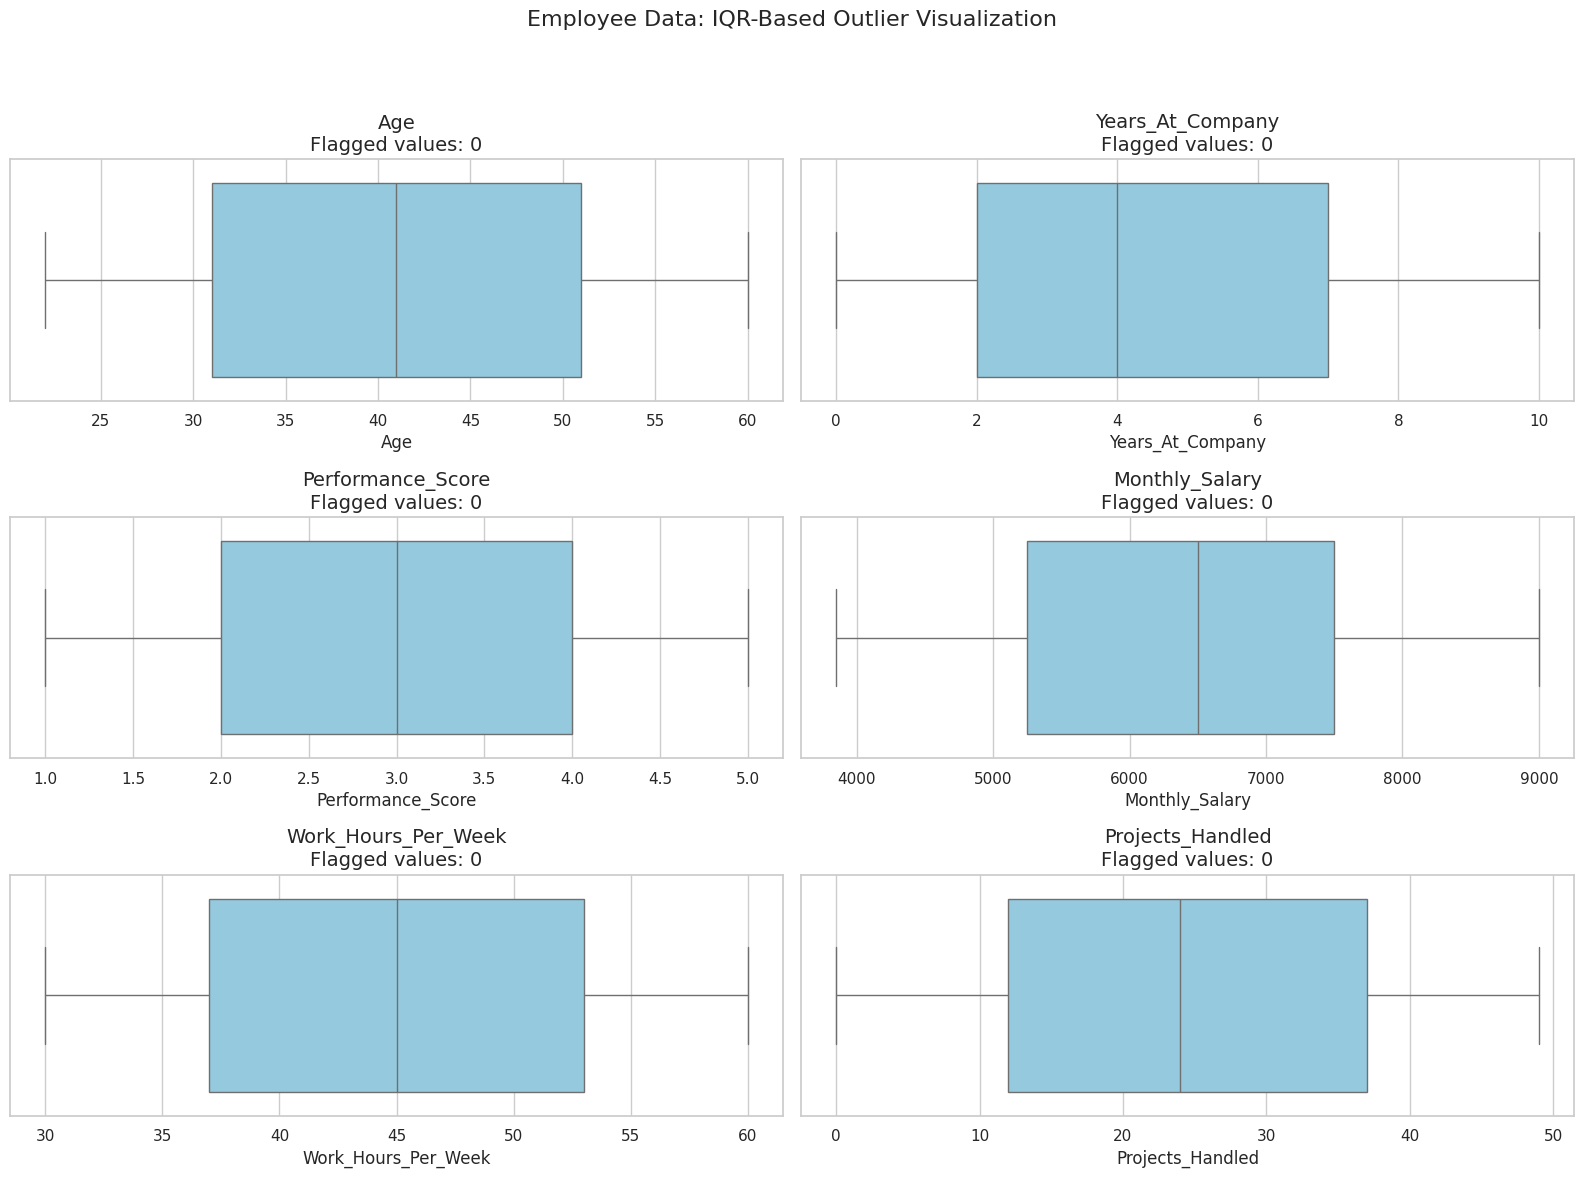

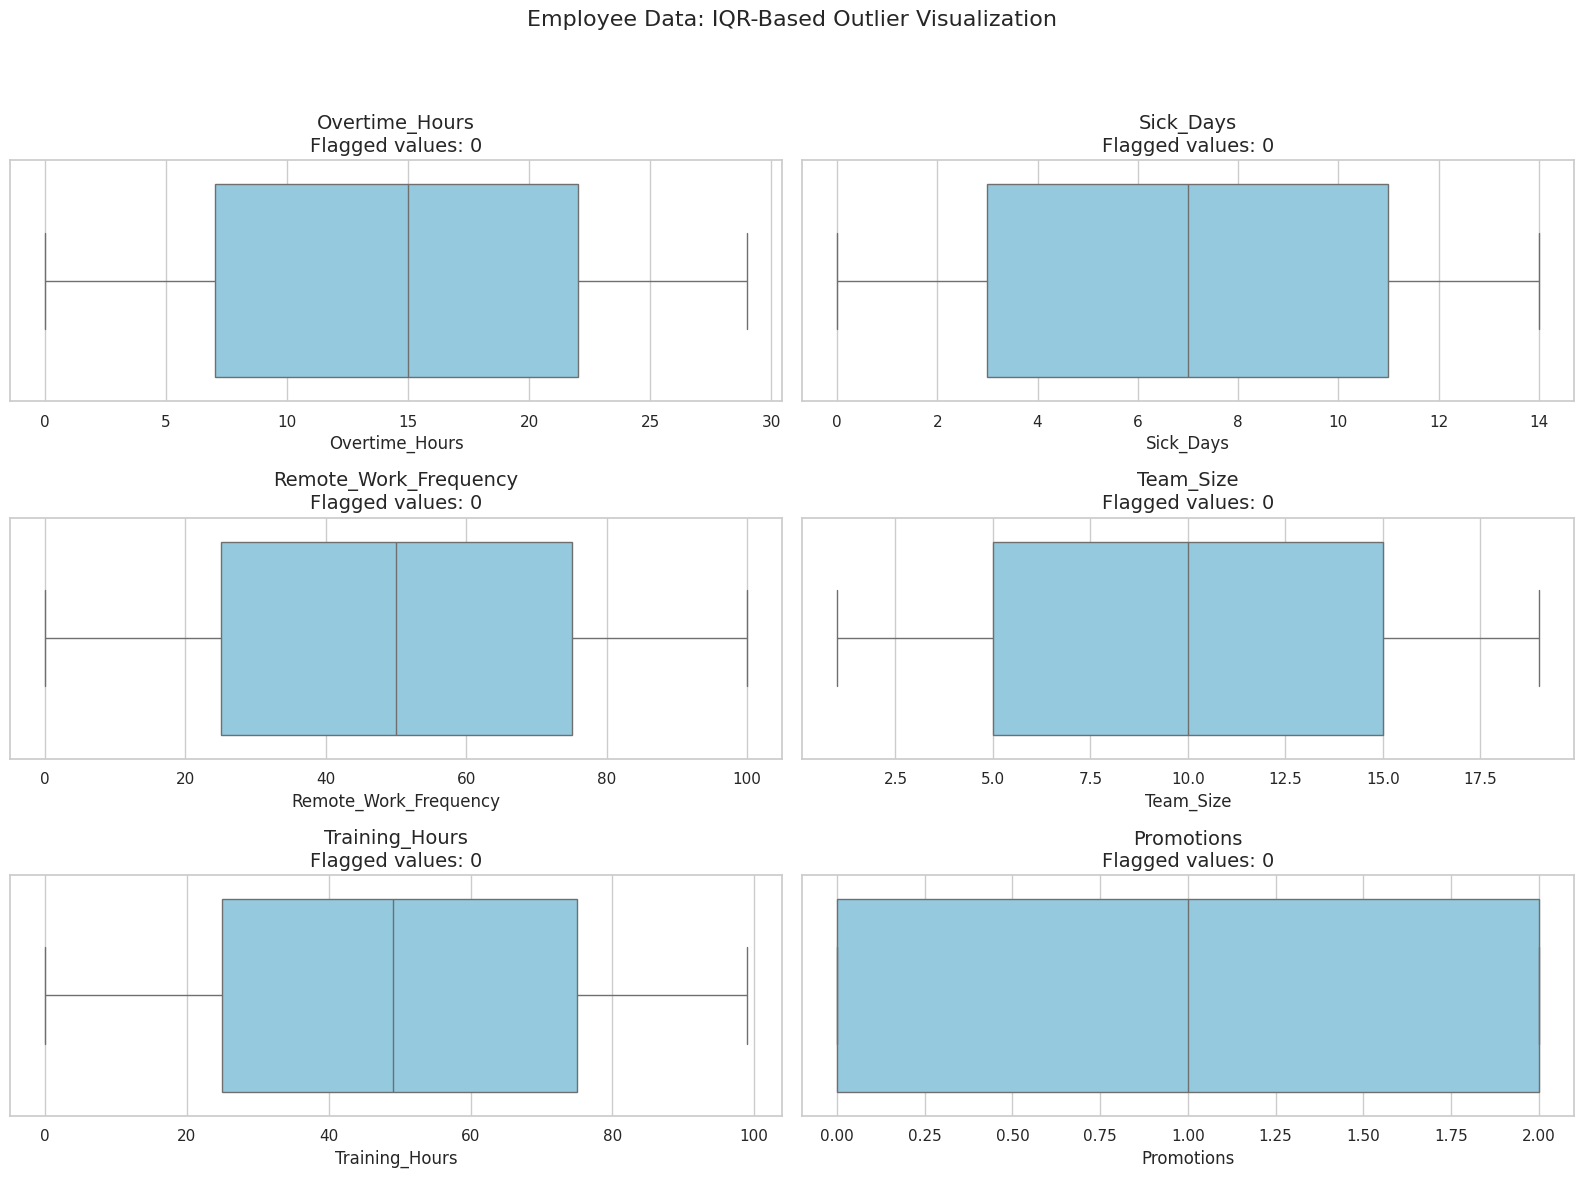

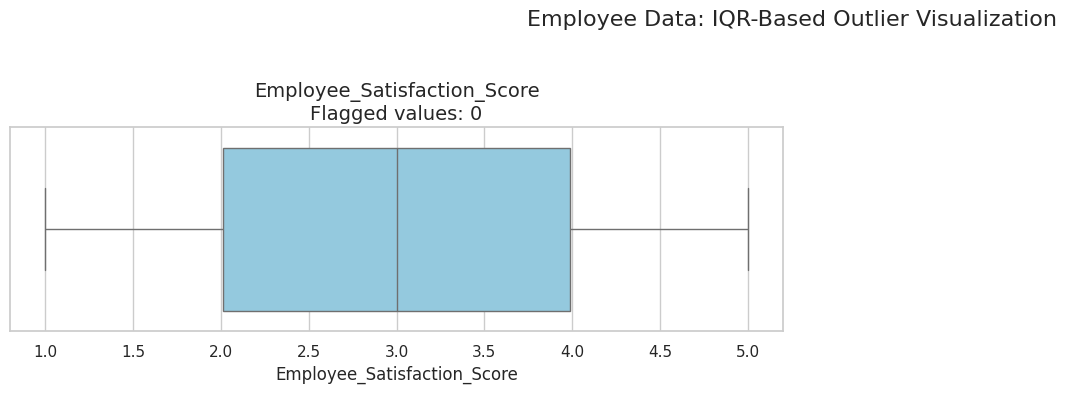

Red points represent values outside the 1.5 × IQR fences. Overlapping points may appear as a single point; the titles and summary tables show the exact flagged counts.
All rows remain retained.


In [7]:
# Plot each feature separately so different measurement scales remain readable.
# Whiskers use the same 1.5 × IQR rule as the detection calculations.
features_per_figure = 6

for start in range(0, len(selected_features), features_per_figure):
    feature_batch = selected_features[start:start + features_per_figure]
    subplot_rows = (len(feature_batch) + 1) // 2

    fig, axes = plt.subplots(
        nrows=subplot_rows,
        ncols=2,
        figsize=(16, 4 * subplot_rows),
        squeeze=False
    )

    for ax, feature in zip(axes.flat, feature_batch):
        values = numerical_df[feature].dropna()
        flagged_count = int(outlier_flags[feature].sum())

        if values.empty:
            ax.text(
                0.5, 0.5,
                "No non-missing values available",
                ha="center",
                va="center",
                transform=ax.transAxes
            )
        else:
            sns.boxplot(
                x=values,
                ax=ax,
                whis=1.5,
                showfliers=True,
                color="skyblue",
                flierprops={
                    "marker": "o",
                    "markerfacecolor": "crimson",
                    "markeredgecolor": "crimson",
                    "markersize": 4,
                    "alpha": 0.6
                }
            )

        ax.set_title(f"{feature}\nFlagged values: {flagged_count:,}")
        ax.set_xlabel(feature)
        ax.set_ylabel("")

    # Hide unused subplot spaces.
    for ax in list(axes.flat)[len(feature_batch):]:
        ax.set_visible(False)

    fig.suptitle(
        "Employee Data: IQR-Based Outlier Visualization",
        fontsize=16
    )
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

print(
    "Red points represent values outside the 1.5 × IQR fences. "
    "Overlapping points may appear as a single point; "
    "the titles and summary tables show the exact flagged counts."
)
print("All rows remain retained.")

## Interpretation and Outlier Handling Decision

### Statistical Outliers Versus Invalid Data

A statistical outlier is a value outside the fences calculated using the 1.5 × IQR rule. It is unusual relative to the distribution of that feature, but it is not automatically incorrect.

In employee data, an unusually high or low measurement may represent a legitimate difference between employees. Numerically encoded ordinal scores also require interpretation against their permitted rating scale.

Invalid data violates a known rule, such as a negative number of hours worked or a score outside its documented scale. Such violations require separate validation; the IQR rule alone cannot establish them.

### Interpreting the Reported Results

The summary table and flagged counts show the values identified by the IQR rule, including features with zero flags. The boxplots illustrate these distributions, with flagged values displayed as red points.

A row can be flagged in several features. Therefore, the total number of flagged values and the number of distinct flagged rows describe different aspects of the results.

A zero flagged count means that no observed values fall outside the calculated fences. It does not prove that every value is valid.

### Why No Removal Was Applied

The project found that no outlier removal was required. This notebook follows that decision and uses IQR flags for reporting and interpretation.

Statistical unusualness alone does not justify deleting an employee record. Removing records solely because they cross an IQR fence could discard legitimate variation and change the dataset's distribution.

No rows were removed, and no flagged values were capped or replaced. All original rows remain available for subsequent analysis.

## Final Conclusion

This notebook demonstrates my contribution to **Outlier Detection and Handling** using the Employee Performance and Productivity dataset.

Numerical features and numerically encoded ordinal scores were selected, while identifiers were excluded. The IQR method was used to calculate feature-specific fences and flag values outside those fences.

The visible summary tables report flagged counts and percentages for every selected feature, including those with zero flags. Distinct flagged rows were counted separately to avoid counting the same record multiple times. Boxplots support interpretation of the results.

IQR flags indicate statistical unusualness rather than confirmed data errors. Their interpretation requires consideration of each feature's meaning and valid range.

The project found that no outlier removal was required. **All original rows were retained, and no values were capped or replaced.** Row-count checks confirm that the detection process preserved the dataset.